# 03 · Satış Tahmini ve Geriye Dönük Test

**Soru:** Açık pipeline'dan önümüzdeki 120 günde ne kadar gelir beklemeliyiz ve hangi yönteme güvenebiliriz?

Bir tahmin yöntemini değerlendirmenin tek dürüst yolu, onu geçmişte **o gün bilinen bilgiyle** çalıştırıp
gerçekleşenle karşılaştırmaktır. Her ayın başında:

1. O gün açık olan fırsatlar aşama geçmişinden yeniden kurulur (o günkü aşama, o güne kadarki süre ve indirim).
2. Üç yöntemle önümüzdeki 120 günün geliri tahmin edilir. Model yalnızca o güne kadar bilinen veriyle eğitilir.
3. Sonraki 120 günde bu fırsatlardan gerçekten kazanılan gelirle karşılaştırılır.

In [1]:
import sys
import warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
sys.path.insert(0, str(Path.cwd().parent / "pipeline"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analytics as a

plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
STAGE_TR = {"Prospecting": "Potansiyel", "Qualification": "Nitelendirme", "Proposal": "Teklif", "Negotiation": "Müzakere", "Won": "Kazanıldı", "Lost": "Kaybedildi"}

data = a.load()
con = a.connect()
print(f"{len(data.deals):,} fırsat · {len(data.history):,} aşama geçişi · analiz tarihi {data.as_of.date()}")

6,613 fırsat · 22,035 aşama geçişi · analiz tarihi 2026-10-31


In [2]:
cutoffs = list(pd.date_range("2025-10-01", data.as_of - pd.Timedelta(days=a.HORIZON_DAYS), freq="MS"))
bt = a.backtest(data, cutoffs)
bt

,cutoff,open_deals,pipeline,actual,naive,stage,model
0,2025-10-01,379,"3,377,796.800","290,183.000","772,628.639","1,171,592.317","589,613.230"
1,2025-11-01,420,"3,715,329.300","631,069.000","810,430.782","1,325,888.692","699,296.079"
2,2025-12-01,475,"4,299,168.700","716,497.000","945,575.102","1,562,779.520","804,426.935"
3,2026-01-01,525,"4,819,400.300","888,735.000","1,052,278.231","1,768,429.764","918,604.308"
4,2026-02-01,487,"4,514,823.900","702,024.000","1,012,604.417","1,725,338.615","767,846.571"
5,2026-03-01,513,"4,811,035.600","586,202.000","1,092,024.294","1,836,486.358","804,806.466"
6,2026-04-01,531,"4,783,292.100","673,419.000","1,081,362.968","1,746,565.509","753,580.228"
7,2026-05-01,583,"5,207,850.000","650,195.000","1,201,020.222","1,959,503.816","810,781.561"
8,2026-06-01,559,"5,069,700.400","608,380.000","1,155,223.059","1,882,778.156","787,634.623"
9,2026-07-01,571,"5,071,811.600","673,004.000","1,153,025.413","1,898,660.152","778,588.692"


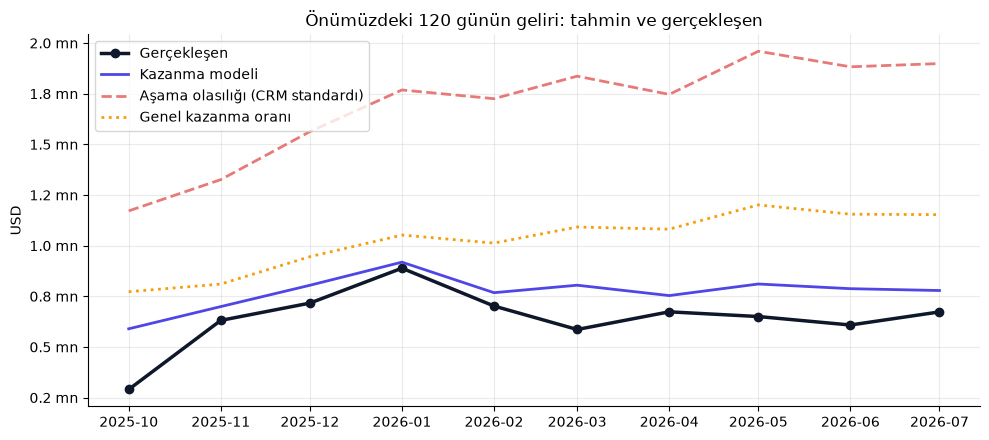

In [3]:
labels = {"model": "Kazanma modeli", "stage": "Aşama olasılığı (CRM standardı)", "naive": "Genel kazanma oranı"}
fig, ax = plt.subplots(figsize=(10, 4.5))
x = pd.to_datetime(bt["cutoff"])
ax.plot(x, bt["actual"], "o-", color="#0f172a", linewidth=2.5, label="Gerçekleşen")
ax.plot(x, bt["model"], color="#4f46e5", linewidth=2, label=labels["model"])
ax.plot(x, bt["stage"], "--", color="#e87979", linewidth=2, label=labels["stage"])
ax.plot(x, bt["naive"], ":", color="#f59e0b", linewidth=2, label=labels["naive"])
ax.set_ylabel("USD"); ax.set_title("Önümüzdeki 120 günün geliri: tahmin ve gerçekleşen"); ax.legend()
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f} mn")
plt.tight_layout()

In [4]:
errors = pd.DataFrame({m: {"MAPE": ((bt[m] - bt["actual"]).abs() / bt["actual"]).mean(),
                          "Ortalama sapma": ((bt[m] - bt["actual"]) / bt["actual"]).mean()} for m in labels}).T
errors.index = errors.index.map(labels)
errors.style.format("{:.1%}")

,MAPE,Ortalama sapma
Kazanma modeli,25.8%,25.8%
Aşama olasılığı (CRM standardı),174.2%,174.2%
Genel kazanma oranı,68.2%,68.2%


**Bulgu:** CRM'lerin standart ağırlıklı pipeline yöntemi geliri sistematik olarak çok yüksek tahmin ediyor. Sebebi
notebook 01 ve 02'de görüldü: açık fırsatların yarıdan fazlası takılmış ve bu yöntem onları aktif fırsatlar gibi sayıyor.
Model, aşamada geçen süreyi ve fırsat yaşını hesaba kattığı için gerçeğe çok daha yakın.

Modelde de pozitif bir sapma var. Olası nedenler: ilk aylarda eğitim verisinin az olması ve tutar tahmininde liste fiyatı
kullanılması (gerçekleşen tutar küçük farklarla sapabilir). Bu sapma izlenmeli; gerekirse son dönem hatasıyla
kalibrasyon düzeltmesi yapılabilir.

## Güncel tahmin

In [5]:
train = a.training_rows(data, data.as_of)
model = a.build_model().fit(train[a.CATEGORICAL + a.NUMERIC], train["won"])
open_now = a.snapshot(data, data.as_of)
open_now["p_model"] = model.predict_proba(open_now[a.CATEGORICAL + a.NUMERIC])[:, 1]
open_now["p_stage"] = open_now["stage"].map(a.stage_rates(data, data.as_of))
overall = data.deals.loc[data.deals["resolved"], "won"].mean()
pd.Series({
    "Açık fırsat": len(open_now),
    "Ağırlıksız pipeline": open_now["amount"].sum(),
    labels["naive"]: (open_now["amount"] * overall).sum(),
    labels["stage"]: (open_now["amount"] * open_now["p_stage"]).sum(),
    labels["model"]: (open_now["amount"] * open_now["p_model"]).sum(),
}).map(lambda v: f"{v:,.0f}")

Açık fırsat                              724
Ağırlıksız pipeline                6,317,828
Genel kazanma oranı                1,439,722
Aşama olasılığı (CRM standardı)    2,368,091
Kazanma modeli                       803,290
dtype: object

## Karar önerisi

- Gelir hedefleri ve nakit planlaması, aşama olasılığıyla değil model tahminiyle yapılmalı.
- Model olasılığı aşama olasılığından çok düşük olan fırsatlar (çoğunlukla takılmış fırsatlar) satış yöneticisiyle
  gözden geçirilip ya ilerletilmeli ya da kapatılmalı. Bu temizlik, standart yöntemin hatasını da doğrudan azaltır.
- Geriye dönük test her ay yeniden çalıştırılmalı: modelin hatası izlenmeden ona güvenilmemeli.